# Tugas - Klasifikasi dengan Support Vector Machine (SVM)

| Nama | NRP |
|------|-----|
| Isi Nama Kalian | Isi NRP Kalian |

## Deskripsi Tugas
Pada tugas ini, kalian akan membangun model SVM Classifier untuk menyelesaikan sebuah masalah klasifikasi.

Dataset dapat diakses melalui link berikut:
[Link dataset akan diinformasikan terpisah]

Tujuan utama dari tugas ini adalah memahami cara kerja SVM secara praktik, khususnya:
1. Perbedaan hasil antara kernel Linear dan kernel RBF
2. Pengaruh parameter `C` dan `gamma` terhadap gejala overfitting/underfitting

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat struktur data, dan distribusi label.
2. Preprocessing
   - Memproses data agar siap digunakan dalam membangun model, termasuk feature scaling.
3. Eksperimen Model
   - Bangun model SVM dengan kernel Linear dan kernel RBF.
   - Lakukan eksperimen regularisasi dengan variasi nilai `C` dan `gamma`.
4. Evaluasi Model
   - Hitung metrik evaluasi dan visualisasikan hasilnya.
5. Analisis dan Kesimpulan
   - Bandingkan hasil eksperimen dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [1]:
%matplotlib inline

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, classification_report, confusion_matrix)
from sklearn.decomposition import PCA

sns.set_theme(style='whitegrid')
RANDOM_STATE = 42
C_VALUE = 1.0


In [2]:
df = pd.read_csv('../Dataset/data.csv')

print('Jumlah baris dan kolom :', df.shape)
print('Jumlah missing value   :', df.isna().sum().sum())
print('Jumlah duplikat        :', df.duplicated().sum())

# Kolom 'Unnamed: 32' (akibat trailing comma pada header CSV) seluruhnya kosong -> buang.
# Membuang kolom yang 100% kosong tidak memanfaatkan informasi target, sehingga tidak menimbulkan data leakage.
empty_cols = [c for c in df.columns if df[c].isna().all()]
if empty_cols:
    df = df.drop(columns=empty_cols)
    print('Kolom 100% kosong dibuang:', empty_cols)
print('Shape setelah pembuangan kolom kosong:', df.shape)

print('\nTipe data:')
print(df.dtypes.value_counts())
print('\n5 baris pertama:')
display(df.head())
print('\nStatistik deskriptif:')
display(df.describe().T)


Jumlah baris dan kolom : (569, 33)
Jumlah missing value   : 569
Jumlah duplikat        : 0
Kolom 100% kosong dibuang: ['Unnamed: 32']
Shape setelah pembuangan kolom kosong: (569, 32)

Tipe data:
float64    30
int64       1
str         1
Name: count, dtype: int64

5 baris pertama:


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678



Statistik deskriptif:


,count,mean,std,min,25%,50%,75%,max
id,569.0,3.037183e+07,1.250206e+08,8670.000000,869218.000000,906024.000000,8.813129e+06,9.113205e+08
radius_mean,569.0,1.412729e+01,3.524049e+00,6.981000,11.700000,13.370000,1.578000e+01,2.811000e+01
texture_mean,569.0,1.928965e+01,4.301036e+00,9.710000,16.170000,18.840000,2.180000e+01,3.928000e+01
perimeter_mean,569.0,9.196903e+01,2.429898e+01,43.790000,75.170000,86.240000,1.041000e+02,1.885000e+02
area_mean,569.0,6.548891e+02,3.519141e+02,143.500000,420.300000,551.100000,7.827000e+02,2.501000e+03
smoothness_mean,569.0,9.636028e-02,1.406413e-02,0.052630,0.086370,0.095870,1.053000e-01,1.634000e-01
compactness_mean,569.0,1.043410e-01,5.281276e-02,0.019380,0.064920,0.092630,1.304000e-01,3.454000e-01
concavity_mean,569.0,8.879932e-02,7.971981e-02,0.000000,0.029560,0.061540,1.307000e-01,4.268000e-01
concave points_mean,569.0,4.891915e-02,3.880284e-02,0.000000,0.020310,0.033500,7.400000e-02,2.012000e-01
symmetry_mean,569.0,1.811619e-01,2.741428e-02,0.106000,0.161900,0.179200,1.957000e-01,3.040000e-01


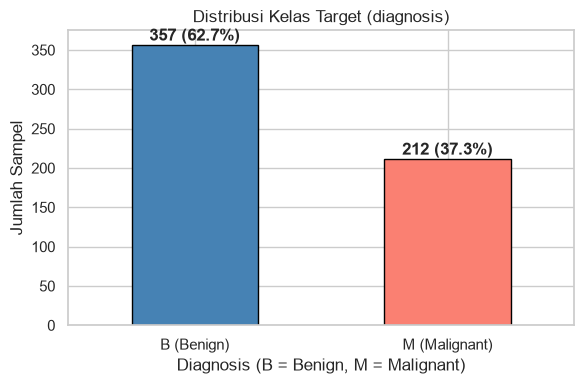

Rasio kelas: B = 0.627 | M = 0.373
-> Dataset cukup seimbang (tidak tergolong imbalanced), jadi akurasi masih metrik yang valid, namun precision/recall tetap dipantau karena kelas M lebih sedikit.


In [3]:
proporsi = df['diagnosis'].value_counts().reindex(['B', 'M'])
ax = proporsi.plot(kind='bar', color=['steelblue', 'salmon'], edgecolor='black', figsize=(6, 4))
ax.set_title('Distribusi Kelas Target (diagnosis)')
ax.set_xlabel('Diagnosis (B = Benign, M = Malignant)')
ax.set_ylabel('Jumlah Sampel')
ax.set_xticklabels(['B (Benign)', 'M (Malignant)'], rotation=0)
for i, v in enumerate(proporsi):
    ax.text(i, v + 5, f'{v} ({v / proporsi.sum() * 100:.1f}%)', ha='center', fontweight='bold')
plt.tight_layout()
plt.show()

print('Rasio kelas: B =', round(proporsi["B"] / proporsi.sum(), 3),
      '| M =', round(proporsi["M"] / proporsi.sum(), 3))
print('-> Dataset cukup seimbang (tidak tergolong imbalanced), jadi akurasi masih metrik yang valid, '
      'namun precision/recall tetap dipantau karena kelas M lebih sedikit.')


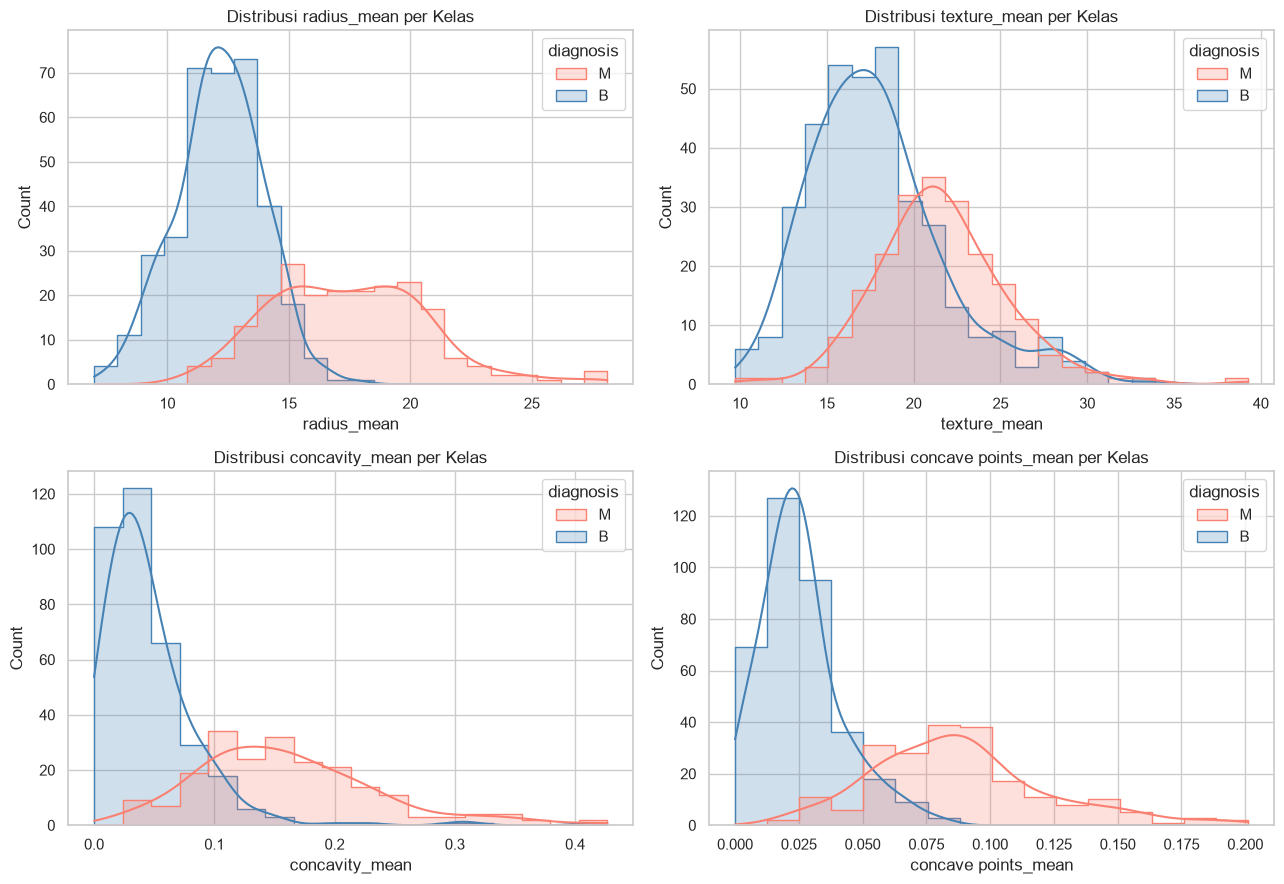

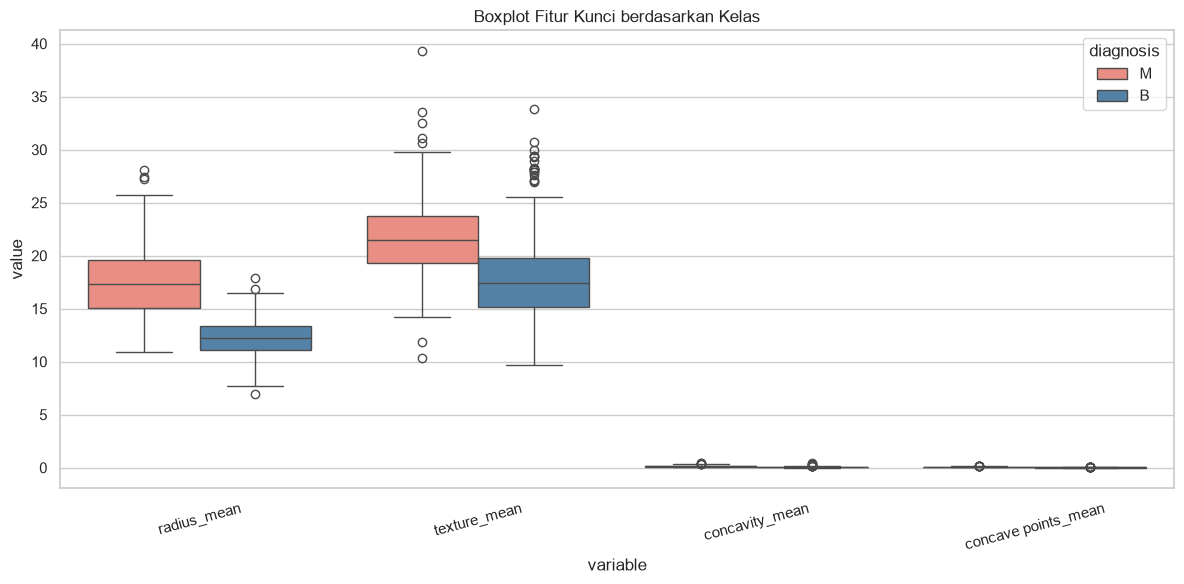

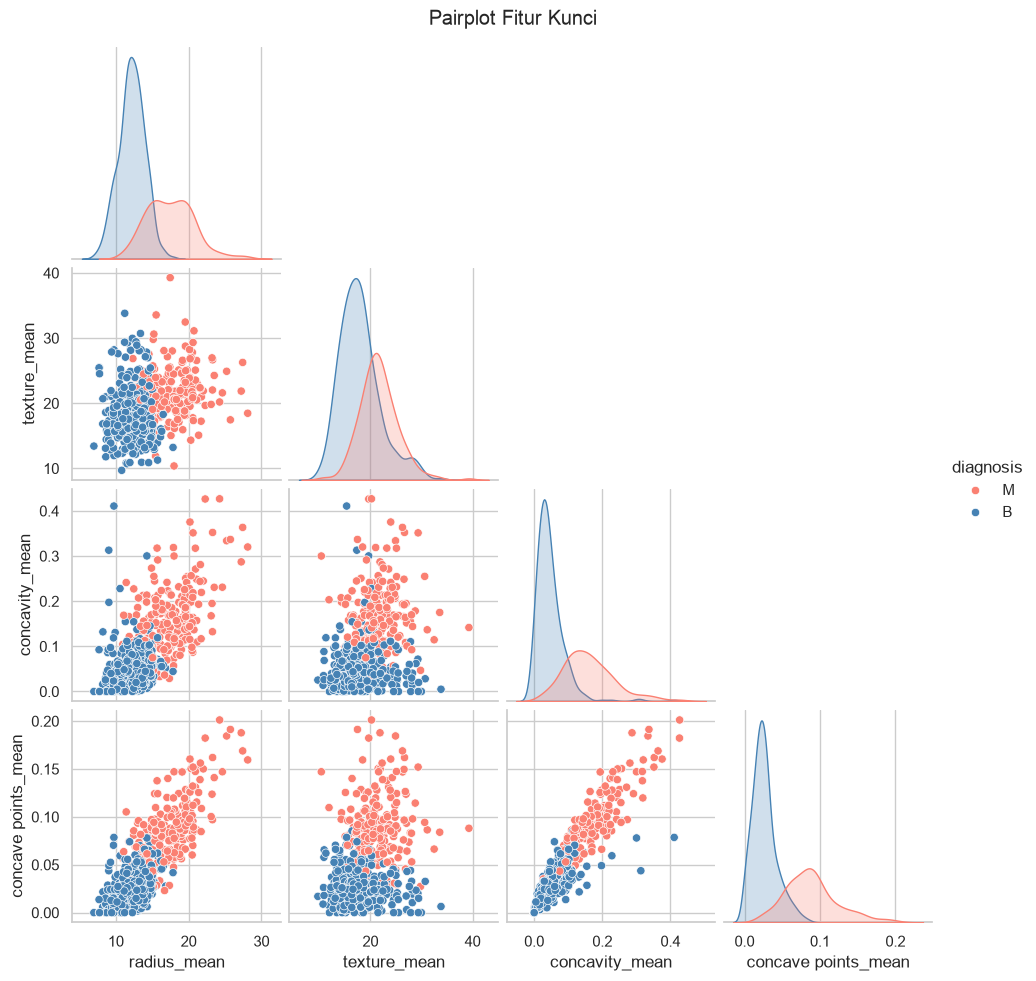

In [4]:
key_features = ['radius_mean', 'texture_mean', 'concavity_mean', 'concave points_mean']

fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, feat in zip(axes.ravel(), key_features):
    sns.histplot(data=df, x=feat, hue='diagnosis', kde=True, element='step',
                 palette={'B': 'steelblue', 'M': 'salmon'}, ax=ax, legend=True)
    ax.set_title(f'Distribusi {feat} per Kelas')
plt.tight_layout()
plt.show()

plt.figure(figsize=(12, 6))
df_melt = df.melt(id_vars='diagnosis', value_vars=key_features)
sns.boxplot(data=df_melt, x='variable', y='value', hue='diagnosis',
            palette={'B': 'steelblue', 'M': 'salmon'})
plt.xticks(rotation=15)
plt.title('Boxplot Fitur Kunci berdasarkan Kelas')
plt.tight_layout()
plt.show()

g = sns.pairplot(df[key_features + ['diagnosis']], hue='diagnosis',
                 palette={'B': 'steelblue', 'M': 'salmon'}, corner=True, height=2.4)
g.fig.suptitle('Pairplot Fitur Kunci', y=1.02)
plt.show()


## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

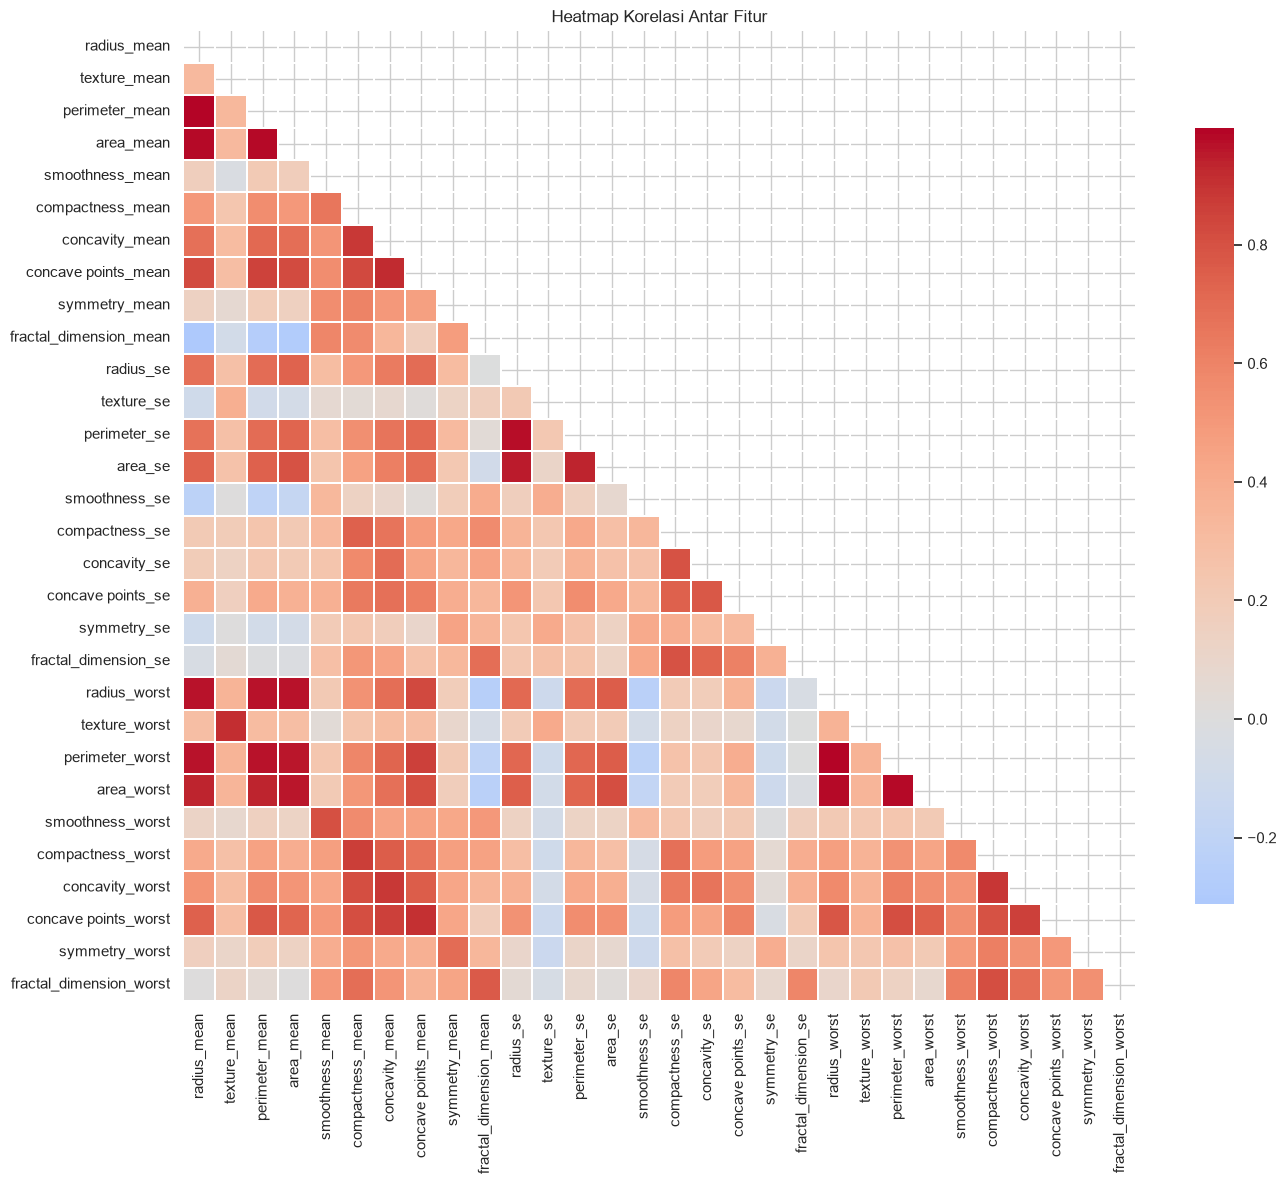

In [5]:
# Korelasi antar fitur (sebagian besar fitur saling berkorelasi tinggi karena berasal dari turunan yang sama)
plt.figure(figsize=(14, 12))
corr = df.drop(columns=['id']).corr(numeric_only=True)
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, cmap='coolwarm', center=0, linewidths=0.3,
            annot=False, fmt='.2f', cbar_kws={'shrink': 0.8})
plt.title('Heatmap Korelasi Antar Fitur')
plt.tight_layout()
plt.show()


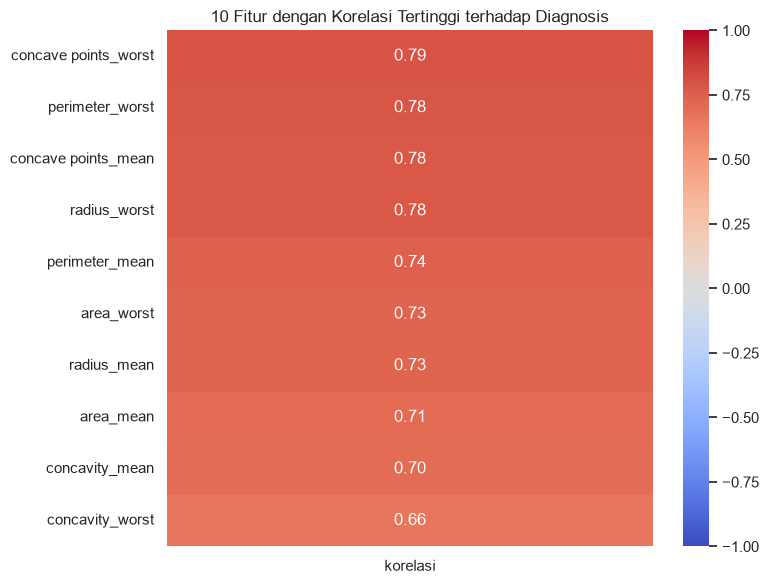

concave points_worst    0.794
perimeter_worst         0.783
concave points_mean     0.777
radius_worst            0.776
perimeter_mean          0.743
area_worst              0.734
radius_mean             0.730
area_mean               0.709
concavity_mean          0.696
concavity_worst         0.660


In [6]:
# Fitur yang paling berkorelasi dengan target (M=1)
df_eda = df.copy()
df_eda['diagnosis_enc'] = (df_eda['diagnosis'] == 'M').astype(int)
corr_target = (df_eda.drop(columns=['id', 'diagnosis'])
               .corr()['diagnosis_enc'].drop('diagnosis_enc').sort_values(ascending=False))

plt.figure(figsize=(8, 6))
sns.heatmap(corr_target.head(10).to_frame(name='korelasi'), annot=True, cmap='coolwarm',
            center=0, vmin=-1, vmax=1, fmt='.2f')
plt.title('10 Fitur dengan Korelasi Tertinggi terhadap Diagnosis')
plt.tight_layout()
plt.show()
print(corr_target.head(10).round(3).to_string())


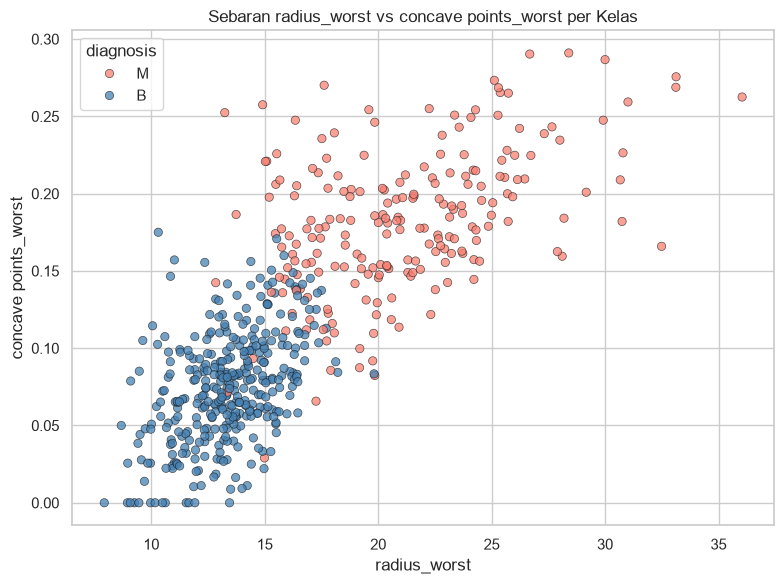

,korelasi_dengan_target
concave points_worst,0.794
perimeter_worst,0.783
concave points_mean,0.777
radius_worst,0.776
perimeter_mean,0.743
area_worst,0.734


In [7]:
# Sebaran dua fitur terkuat: apakah ada batas pemisah yang jelas antar kelas?
plt.figure(figsize=(8, 6))
sns.scatterplot(data=df, x='radius_worst', y='concave points_worst', hue='diagnosis',
                palette={'B': 'steelblue', 'M': 'salmon'}, alpha=0.75, edgecolor='k')
plt.title('Sebaran radius_worst vs concave points_worst per Kelas')
plt.tight_layout()
plt.show()

display(corr_target.head(6).to_frame('korelasi_dengan_target').round(3))


# 2. Preprocessing

In [8]:
missing_per_col = df.isna().sum()
print('Missing value per kolom:')
print(missing_per_col[missing_per_col > 0] if missing_per_col.sum() > 0
      else 'Tidak ada missing value (kolom kosong 100% sudah dibuang saat load).')

# Strategi penanganan missing value tanpa data leakage:
#   - fitur numerik     : imputasi dengan median yang hanya dihitung dari TRAIN set (fit imputer setelah split)
#   - fitur kategorikal : imputasi dengan modus dari TRAIN set
#   - kolom yang 100% kosong : dibuang (sudah dilakukan saat load, tidak memanfaatkan informasi target)
# Karena pada dataset ini tidak ada missing value tersisa, maka tidak ada imputasi yang dilakukan.


Missing value per kolom:
Tidak ada missing value (kolom kosong 100% sudah dibuang saat load).


In [9]:
# Kolom 'diagnosis' adalah satu-satunya fitur kategorikal dan sekaligus target -> Label Encoding (B=0, M=1)
df['diagnosis'] = df['diagnosis'].map({'B': 0, 'M': 1})

# Kolom 'id' hanyalah identifier unik, bukan fitur prediktif -> buang agar tidak menambah dimensi/noise
# Tidak ada fitur kategorikal lain, sehingga One-Hot Encoding tidak diperlukan.
print(df['diagnosis'].value_counts().rename({0: 'B (Benign)', 1: 'M (Malignant)'}))


diagnosis
B (Benign)       357
M (Malignant)    212
Name: count, dtype: int64


In [10]:
X = df.drop(columns=['id', 'diagnosis'])
y = df['diagnosis']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y)

print('X_train:', X_train.shape, '| X_test:', X_test.shape)
print('Proporsi kelas train:', dict(y_train.value_counts().sort_index()),
      '->', (y_train.value_counts(normalize=True).sort_index().round(3)).to_dict())
print('Proporsi kelas test :', dict(y_test.value_counts().sort_index()),
      '->', (y_test.value_counts(normalize=True).sort_index().round(3)).to_dict())


X_train: (455, 30) | X_test: (114, 30)
Proporsi kelas train: {0: np.int64(285), 1: np.int64(170)} -> {0: 0.626, 1: 0.374}
Proporsi kelas test : {0: np.int64(72), 1: np.int64(42)} -> {0: 0.632, 1: 0.368}


**Catatan penting:** SVM adalah algoritma berbasis jarak (margin dihitung dari posisi antar titik data), sehingga sangat sensitif terhadap skala fitur. Fitur dengan rentang nilai besar bisa mendominasi perhitungan jarak meskipun sebenarnya tidak lebih penting. Lakukan **feature scaling** (misalnya `StandardScaler`) pada fitur numerik sebelum training. Ingat: `fit` scaler hanya pada train set, lalu `transform` ke train dan test set, agar tidak terjadi data leakage.

In [11]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit HANYA pada train
X_test_scaled = scaler.transform(X_test)         # transform saja pada test (tanpa data leakage)

print('Mean fitur train setelah scaling (seharusnya ~0):',
      np.round(X_train_scaled.mean(axis=0).mean(), 6))
print('Std  fitur train setelah scaling (seharusnya ~1):',
      np.round(X_train_scaled.std(axis=0).mean(), 6))


Mean fitur train setelah scaling (seharusnya ~0): 0.0
Std  fitur train setelah scaling (seharusnya ~1): 1.0


# 3. Eksperimen Model

## 3.1 SVM dengan Kernel Linear

Kernel Linear mencari hyperplane pemisah berupa garis/bidang lurus, tanpa proyeksi ke dimensi yang lebih tinggi. Cocok digunakan sebagai baseline, terutama jika dari hasil EDA data terlihat cukup terpisah secara linear.

In [12]:
svm_linear = SVC(kernel='linear', C=C_VALUE, random_state=RANDOM_STATE)
svm_linear.fit(X_train_scaled, y_train)
print('Model Linear selesai dilatih | jumlah support vector:',
      svm_linear.support_vectors_.shape[0])


Model Linear selesai dilatih | jumlah support vector: 38


In [13]:
y_pred_linear = svm_linear.predict(X_test_scaled)
print('Akurasi SVM Linear pada test set:',
      round(accuracy_score(y_test, y_pred_linear), 4))


Akurasi SVM Linear pada test set: 0.9649


## 3.2 SVM dengan Kernel RBF

Kernel RBF (Radial Basis Function) memproyeksikan data ke ruang berdimensi lebih tinggi melalui kernel trick, sehingga mampu menangani batas keputusan yang non-linear.

In [14]:
svm_rbf = SVC(kernel='rbf', C=C_VALUE, gamma='scale', random_state=RANDOM_STATE)
svm_rbf.fit(X_train_scaled, y_train)
print('Model RBF selesai dilatih | jumlah support vector:',
      svm_rbf.support_vectors_.shape[0])


Model RBF selesai dilatih | jumlah support vector: 107


In [15]:
y_pred_rbf = svm_rbf.predict(X_test_scaled)
print('Akurasi SVM RBF pada test set:',
      round(accuracy_score(y_test, y_pred_rbf), 4))


Akurasi SVM RBF pada test set: 0.9737


## 3.3 Eksperimen Regularisasi: Pengaruh C dan Gamma terhadap Overfitting

Parameter `C` mengatur trade-off antara margin lebar dan toleransi kesalahan klasifikasi, sedangkan `gamma` (khusus kernel RBF) mengatur seberapa lokal pengaruh tiap titik data. Pada bagian ini kalian akan mengamati bagaimana perubahan nilai `C` (dan/atau `gamma`) memengaruhi akurasi training dan testing.

In [16]:
C_values = [0.01, 0.1, 1, 10, 100]
rbf_models = {}

for C in C_values:
    model = SVC(kernel='rbf', C=C, gamma='scale', random_state=RANDOM_STATE)
    model.fit(X_train_scaled, y_train)
    rbf_models[C] = model
    print(f'Model RBF dengan C={C} selesai dilatih')


Model RBF dengan C=0.01 selesai dilatih
Model RBF dengan C=0.1 selesai dilatih
Model RBF dengan C=1 selesai dilatih
Model RBF dengan C=10 selesai dilatih
Model RBF dengan C=100 selesai dilatih


In [17]:
train_acc, test_acc, sv_count = [], [], []

for C in C_values:
    model = rbf_models[C]
    train_acc.append(accuracy_score(y_train, model.predict(X_train_scaled)))
    test_acc.append(accuracy_score(y_test, model.predict(X_test_scaled)))
    sv_count.append(model.support_vectors_.shape[0])

results_C = pd.DataFrame({
    'C': C_values,
    'Train Accuracy': np.round(train_acc, 4),
    'Test Accuracy': np.round(test_acc, 4),
    'Gap (Train-Test)': np.round(np.array(train_acc) - np.array(test_acc), 4),
    'Jumlah SV': sv_count,
})
display(results_C)


,C,Train Accuracy,Test Accuracy,Gap (Train-Test),Jumlah SV
0,0.01,0.6264,0.6316,-0.0052,341
1,0.10,0.9538,0.9474,0.0065,202
2,1.00,0.9868,0.9737,0.0131,107
3,10.00,0.9890,0.9737,0.0153,82
4,100.00,1.0000,0.9649,0.0351,70


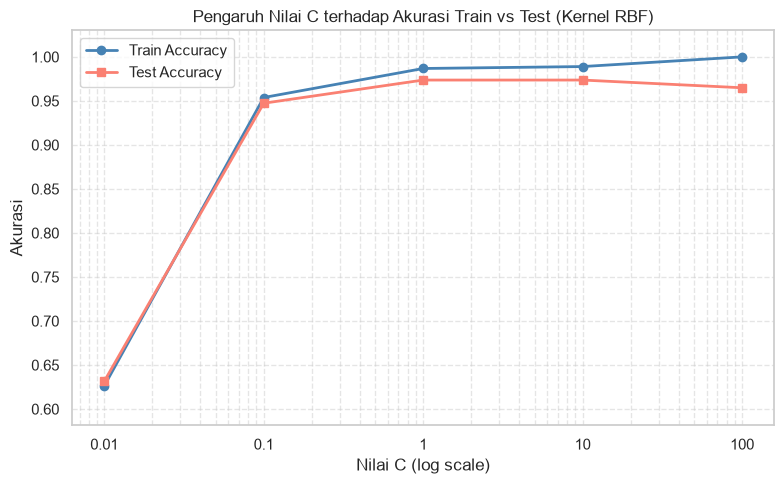

Akurasi test terbaik pada C=1 (0.9737), gap train-test = 0.0131


In [18]:
plt.figure(figsize=(8, 5))
plt.plot(C_values, train_acc, 'o-', label='Train Accuracy', color='steelblue', linewidth=2)
plt.plot(C_values, test_acc, 's-', label='Test Accuracy', color='salmon', linewidth=2)
plt.xscale('log')
plt.xticks(C_values, [str(c) for c in C_values])
plt.xlabel('Nilai C (log scale)')
plt.ylabel('Akurasi')
plt.title('Pengaruh Nilai C terhadap Akurasi Train vs Test (Kernel RBF)')
plt.ylim(min(test_acc) - 0.05, max(train_acc) + 0.03)
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

best_idx = int(np.argmax(test_acc))
print(f'Akurasi test terbaik pada C={C_values[best_idx]} ({test_acc[best_idx]:.4f}), '
      f'gap train-test = {train_acc[best_idx] - test_acc[best_idx]:.4f}')


,gamma,Train Accuracy,Test Accuracy,Gap (Train-Test),Jumlah SV
0,0.001,0.9495,0.9386,0.0109,176
1,0.010,0.9758,0.9561,0.0197,96
2,0.100,0.9890,0.9298,0.0592,194
3,1.000,1.0000,0.6316,0.3684,455


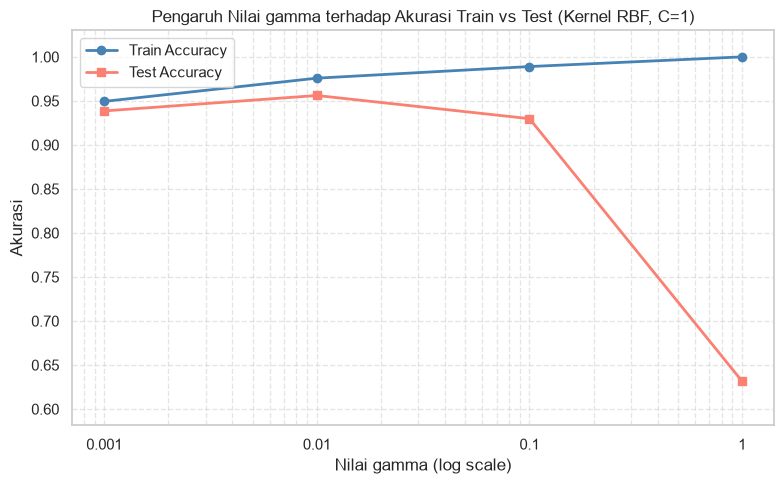

gamma terbaik = 0.01 (test acc 0.9561), gap = 0.0197


In [19]:
# Eksperimen tambahan: pengaruh gamma (C tetap = 1) terhadap overfitting
gamma_values = [0.001, 0.01, 0.1, 1]
train_acc_g, test_acc_g, sv_g = [], [], []

for g in gamma_values:
    m = SVC(kernel='rbf', C=C_VALUE, gamma=g, random_state=RANDOM_STATE)
    m.fit(X_train_scaled, y_train)
    train_acc_g.append(accuracy_score(y_train, m.predict(X_train_scaled)))
    test_acc_g.append(accuracy_score(y_test, m.predict(X_test_scaled)))
    sv_g.append(m.support_vectors_.shape[0])

results_gamma = pd.DataFrame({
    'gamma': gamma_values,
    'Train Accuracy': np.round(train_acc_g, 4),
    'Test Accuracy': np.round(test_acc_g, 4),
    'Gap (Train-Test)': np.round(np.array(train_acc_g) - np.array(test_acc_g), 4),
    'Jumlah SV': sv_g,
})
display(results_gamma)

plt.figure(figsize=(8, 5))
plt.plot(gamma_values, train_acc_g, 'o-', label='Train Accuracy', color='steelblue', linewidth=2)
plt.plot(gamma_values, test_acc_g, 's-', label='Test Accuracy', color='salmon', linewidth=2)
plt.xscale('log')
plt.xticks(gamma_values, [str(g) for g in gamma_values])
plt.xlabel('Nilai gamma (log scale)')
plt.ylabel('Akurasi')
plt.title('Pengaruh Nilai gamma terhadap Akurasi Train vs Test (Kernel RBF, C=1)')
plt.ylim(min(min(test_acc_g), min(train_acc_g)) - 0.05, max(max(train_acc_g), max(test_acc_g)) + 0.03)
plt.legend()
plt.grid(True, which='both', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

best_g = int(np.argmax(test_acc_g))
print(f'gamma terbaik = {gamma_values[best_g]} (test acc {test_acc_g[best_g]:.4f}), '
      f'gap = {train_acc_g[best_g] - test_acc_g[best_g]:.4f}')


# 4. Evaluasi Model

In [20]:
def evaluate(y_true, y_pred):
    return {
        'Accuracy': accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, pos_label=1),
        'Recall': recall_score(y_true, y_pred, pos_label=1),
        'F1-Score': f1_score(y_true, y_pred, pos_label=1),
    }

metrics = pd.DataFrame({
    'SVM Linear': evaluate(y_test, y_pred_linear),
    'SVM RBF': evaluate(y_test, y_pred_rbf),
}).T
display(metrics.round(4))

print('Classification report SVM Linear:')
print(classification_report(y_test, y_pred_linear, target_names=['Benign (0)', 'Malignant (1)']))
print('Classification report SVM RBF:')
print(classification_report(y_test, y_pred_rbf, target_names=['Benign (0)', 'Malignant (1)']))


,Accuracy,Precision,Recall,F1-Score
SVM Linear,0.9649,1.0,0.9048,0.950
SVM RBF,0.9737,1.0,0.9286,0.963


Classification report SVM Linear:
               precision    recall  f1-score   support

   Benign (0)       0.95      1.00      0.97        72
Malignant (1)       1.00      0.90      0.95        42

     accuracy                           0.96       114
    macro avg       0.97      0.95      0.96       114
 weighted avg       0.97      0.96      0.96       114

Classification report SVM RBF:
               precision    recall  f1-score   support

   Benign (0)       0.96      1.00      0.98        72
Malignant (1)       1.00      0.93      0.96        42

     accuracy                           0.97       114
    macro avg       0.98      0.96      0.97       114
 weighted avg       0.97      0.97      0.97       114



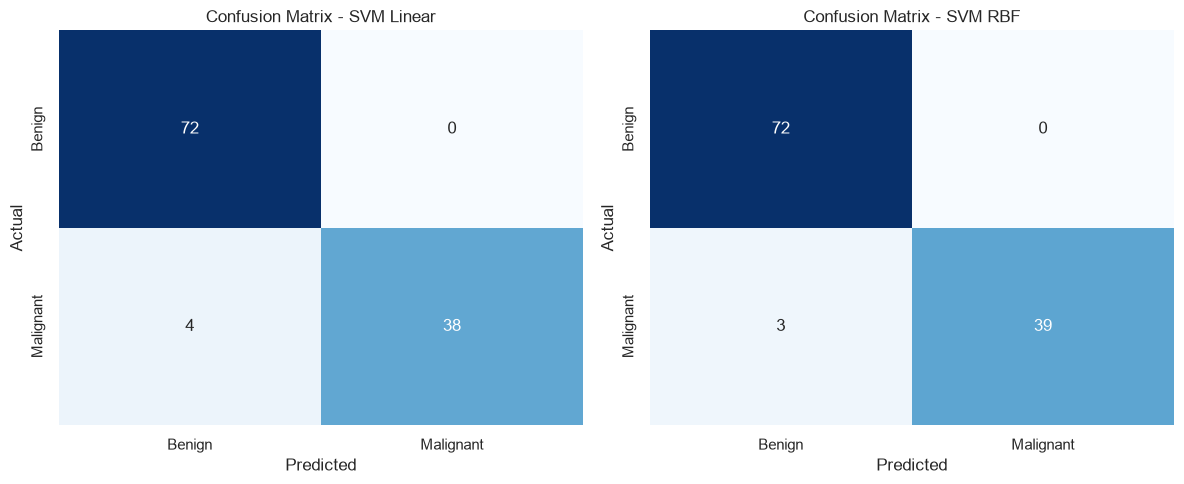

In [21]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, y_pred, title in zip(axes, [y_pred_linear, y_pred_rbf], ['SVM Linear', 'SVM RBF']):
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Benign', 'Malignant'], yticklabels=['Benign', 'Malignant'])
    ax.set_title(f'Confusion Matrix - {title}')
    ax.set_xlabel('Predicted')
    ax.set_ylabel('Actual')
plt.tight_layout()
plt.show()


In [22]:
acc_linear = accuracy_score(y_test, y_pred_linear)
acc_rbf = accuracy_score(y_test, y_pred_rbf)
best_name = 'SVM Linear' if acc_linear >= acc_rbf else 'SVM RBF'
best_model = svm_linear if acc_linear >= acc_rbf else svm_rbf

print('Jumlah support vectors per kelas [Benign, Malignant]:')
print('  Linear :', svm_linear.n_support_, '-> total', svm_linear.n_support_.sum())
print('  RBF    :', svm_rbf.n_support_, '-> total', svm_rbf.n_support_.sum())
print(f'\nModel dengan performa test terbaik: {best_name} '
      f'(akurasi {max(acc_linear, acc_rbf):.4f}) dengan total '
      f'{best_model.support_vectors_.shape[0]} support vectors.')


Jumlah support vectors per kelas [Benign, Malignant]:
  Linear : [19 19] -> total 38
  RBF    : [50 57] -> total 107

Model dengan performa test terbaik: SVM RBF (akurasi 0.9737) dengan total 107 support vectors.


Variance ratio 2 komponen PCA: [0.4459 0.1855] | total: 0.6314


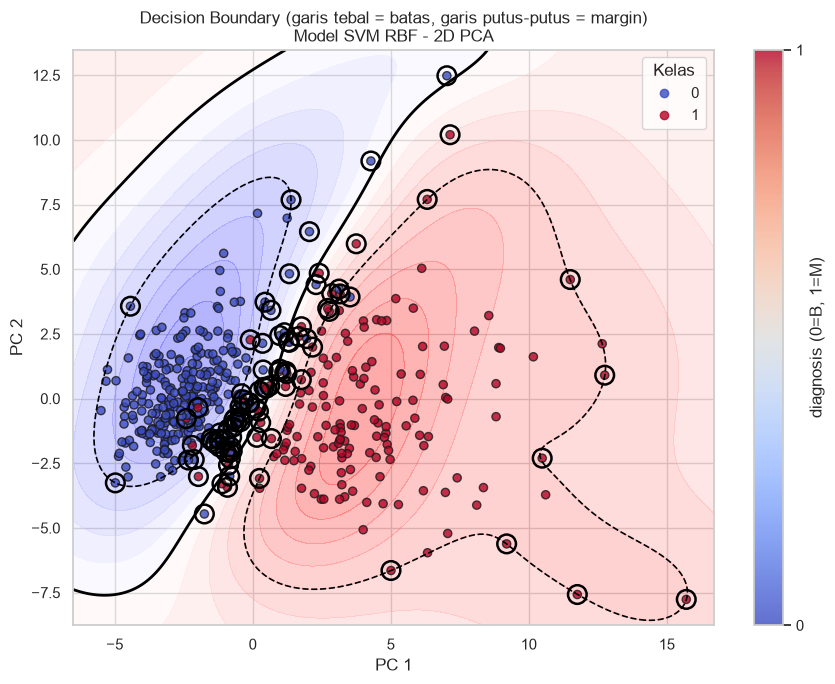

Akurasi model terbaik pada data 2D PCA (train): 0.9407 | (test): 0.9298


In [23]:
pca = PCA(n_components=2, random_state=RANDOM_STATE)
X_train_2d = pca.fit_transform(X_train_scaled)
X_test_2d = pca.transform(X_test_scaled)
print('Variance ratio 2 komponen PCA:',
      np.round(pca.explained_variance_ratio_, 4),
      '| total:', round(pca.explained_variance_ratio_.sum(), 4))

# Model terbaik dilatih ulang pada 2 dimensi PCA agar decision boundary-nya bisa divisualisasikan
model_2d = SVC(kernel=best_model.kernel, C=best_model.C,
               gamma='scale', random_state=RANDOM_STATE)
model_2d.fit(X_train_2d, y_train)

x_min, x_max = X_train_2d[:, 0].min() - 1, X_train_2d[:, 0].max() + 1
y_min, y_max = X_train_2d[:, 1].min() - 1, X_train_2d[:, 1].max() + 1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 400), np.linspace(y_min, y_max, 400))
Z = model_2d.decision_function(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)

plt.figure(figsize=(9, 7))
plt.contourf(xx, yy, Z, levels=20, cmap='bwr', alpha=0.35)
plt.contour(xx, yy, Z, levels=[-1, 0, 1], colors='black',
            linestyles=['--', '-', '--'], linewidths=[1.2, 2, 1.2])
scatter = plt.scatter(X_train_2d[:, 0], X_train_2d[:, 1], c=y_train,
                      cmap='coolwarm', edgecolor='k', s=35, alpha=0.8)
sv = model_2d.support_vectors_
plt.scatter(sv[:, 0], sv[:, 1], s=180, facecolors='none', edgecolors='black',
            linewidths=1.8, label=f'Support vectors ({len(sv)})')
plt.title(f'Decision Boundary (garis tebal = batas, garis putus-putus = margin)\n'
          f'Model {best_name} - 2D PCA')
plt.xlabel('PC 1')
plt.ylabel('PC 2')
plt.legend(*scatter.legend_elements(), title='Kelas', loc='upper right')
plt.colorbar(scatter, ticks=[0, 1], label='diagnosis (0=B, 1=M)')
plt.tight_layout()
plt.show()

print('Akurasi model terbaik pada data 2D PCA (train):',
      round(accuracy_score(y_train, model_2d.predict(X_train_2d)), 4),
      '| (test):', round(accuracy_score(y_test, model_2d.predict(X_test_2d)), 4))


# 5. Analisis

### Hasil Analisis Eksperimen

**1. Perbandingan SVM Linear vs SVM RBF**

| Model | Accuracy | Precision | Recall | F1-Score | Support Vectors |
|-------|----------|-----------|--------|----------|-----------------|
| SVM Linear (C=1) | 0.9649 | 1.0000 | 0.9048 | 0.9500 | 38 |
| SVM RBF (C=1) | 0.9737 | 1.0000 | 0.9286 | 0.9630 | 107 |

Keduanya tidak berbeda signifikan: selisih akurasi hanya **0,88 poin persentase**, yang setara dengan **1 kasus** pada confusion matrix (Linear: 4 FN, RBF: 3 FN; keduanya FP = 0). RBF sedikit lebih unggul karena mampu menangani beberapa titik yang berada di zona tumpang tindih antar kelas.

Hal ini sesuai dengan hasil EDA: fitur-fitur `radius_worst`, `concave points_worst`, `perimeter_worst`, dan sejenisnya berkorelasi sangat tinggi satu sama lain dan berkorelasi kuat dengan target (hingga 0.79), sedangkan scatter plot `radius_worst` vs `concave points_worst` memperlihatkan dua gugus yang relatif terpisah dengan hanya sedikit titik di area transisi. Sebaran semacam ini **hampir linearly separable**, sehingga hyperplane lurus (kernel Linear) sudah hampir optimal; kernel RBF hanya memberi tambahan keunggulan kecil pada data di batas kelas.

**2. Pengaruh nilai C terhadap overfitting/underfitting (kernel RBF)**

| C | Train Acc | Test Acc | Gap | Jumlah SV |
|---|-----------|----------|-----|-----------|
| 0.01 | 0.6264 | 0.6316 | -0.0052 | 341 |
| 0.1 | 0.9538 | 0.9474 | 0.0065 | 202 |
| 1 | 0.9868 | 0.9737 | 0.0131 | 107 |
| 10 | 0.9890 | 0.9737 | 0.0153 | 82 |
| 100 | 1.0000 | 0.9649 | 0.0351 | 70 |

- **C = 0.01 → underfitting.** Akurasi train dan test sama-sama ~63%, yaitu hampir identik dengan proporsi kelas mayoritas. Margin dibuat terlalu lebar sehingga hampir semua data dianggap "boleh salah" dan model gagal belajar pola (341 dari 455 data menjadi support vector).
- **C = 0.1 → 1 adalah daerah terbaik.** Akurasi melompat tajam dan gap train-test masih kecil (≤1,3%).
- **C = 10 → 100 → gejala overfitting mulai muncul.** Mulai C=10 akurasi train terus naik (0,989 → 1,000 sempurna), tetapi akurasi test stagnan di 0,9737 lalu **turun** ke 0,9649 pada C=100, sementara gap melebar dari 1,53% ke 3,51%. Ciri klasik overfitting terlihat jelas pada **C=100**: train naik terus, test berhenti lalu turun. Jumlah support vector juga menyusut (107 → 70) karena margin makin sempit dan model makin "kaku" menghafal data.

Pada eksperimen **gamma** (C=1) juga diperoleh pola serupa: gamma=0.001 cenderung underfit (test 0,9386), **gamma=0.01 terbaik** (test 0,9561), sementara **gamma=1.0 menyebabkan overfitting ekstrem** — train 100% sempurna tetapi test anjlok ke 0,6316, karena pengaruh tiap titik data menjadi terlalu lokal sehingga batas keputusan terlalu kompleks dan tidak mampu mengeneralisasi.

**3. Jumlah support vectors: Linear vs RBF**

- **Linear: 38 SV** (19 Benign, 19 Malignant) — hanya titik-titik yang tepat berada di margin atau melanggarnya. Sedikitnya SV menunjukkan batas keputusan yang sangat sederhana (satu hyperplane lurus), yang justru cocok untuk data yang memang hampir terpisah linear, dan berkontribusi pada generalisasi yang baik meski recall sedikit lebih rendah (4 kasus M terlewat).
- **RBF: 107 SV** (50 Benign, 57 Malignant) — jauh lebih banyak karena batas keputusannya melengkung dan melewati lebih banyak titik dekat batas kelas. Jumlah SV yang lebih besar mencerminkan **kompleksitas model yang lebih tinggi**; trade-off-nya, RBF menangkap 1 kasus M tambahan yang tidak ditangkap Linear, namun kompleksitas ekstra ini juga membuatnya lebih sensitif terhadap nilai C dan gamma (terbukti pada eksperimen, makin besar C/makin besar gamma, perilaku SV dan generalisasi makin berubah drastis).

**4. Visualisasi decision boundary (2D PCA)**

Dua komponen PCA hanya menangkap **63,14%** varians total, dan model terbaik (RBF) yang dilatih ulang pada ruang 2D tersebut hanya mencapai akurasi train 0,9407 / test 0,9298 — lebih rendah dari model 30 fitur asli (0,9737). Ini menunjukkan bahwa informasi pemisahan kelas tersebar di banyak dimensi, bukan hanya dua komponen teratas. Pada plot, batas keputusan berupa kurva lengkung dengan margin (garis putus-putus) dan support vector yang ditandai lingkaran hitam terlihat memisahkan kedua kelas dengan baik, meskipun masih ada beberapa titik yang jatuh di sisi yang salah.


# 6. Kesimpulan dan Saran

### Kesimpulan

1. **Kernel RBF (accuracy 0,9737; F1 0,963) sedikit lebih baik daripada Kernel Linear (accuracy 0,9649; F1 0,950)**, tetapi selisihnya tidak signifikan (hanya 1 kasus). Hal ini terjadi karena sebaran fitur dataset tersebut hampir linearly separable, sehingga batas lurus sudah hampir optimal dan keunggulan non-linear RBF hanya maksimal pada zona tumpang tindih data.
2. **Nilai C terbaik pada eksperimen ini adalah C=1** (akurasi test tertinggi dengan gap train-test masih kecil). **Underfitting** terjadi pada C=0.01 (model mengikuti kelas mayoritas, akurasi ~63%), sedangkan **overfitting mulai terlihat pada C≥10 dan jelas pada C=100** (train 100%, test turun, gap melebar). Pola serupa terjadi pada gamma: **gamma terlalu besar (1.0) membuat model overfit ekstrem** (train 100%, test 63%).
3. **Model RBF menggunakan lebih banyak support vector (107) dibanding Linear (38)**, yang mencerminkan batas keputusan lebih kompleks (melengkung) dan karenanya lebih rentan terhadap perubahan hyperparameter; model Linear yang sederhana justru sudah sangat kompetitif pada data ini.
4. **Precision kedua model sempurna (1.0)** sehingga tidak ada pasien benign yang diprediksi malignant; perbedaan utama ada pada **recall kelas malignant** (Linear 0,90 vs RBF 0,93), di mana RBF lebih aman karena lebih sedikit kasus ganas yang terlewat. Feature scaling (StandardScaler) dan pembagian stratified 80:20 terbukti menjaga proporsi kelas serta mencegah data leakage.

### Saran

1. **Hyperparameter tuning menyeluruh** dengan `GridSearchCV`/`RandomizedSearchCV` + `StratifiedKFold` pada kombinasi `C`, `gamma`, dan `kernel`, karena test set hanya 114 sampel sehingga satu kali split masih cukup berisiko.
2. **Mencoba kernel lain** (Polynomial, Sigmoid) sebagai pembanding, mengingat keunggulan RBF atas Linear tipis — bisa jadi kernel lain memberi hasil lebih stabil.
3. **Mengutamakan recall kelas malignant**: gunakan `class_weight='balanced'` atau penyesuaian threshold decision function, karena pada aplikasi medis salah-deteksi pasien ganas (FN) jauh lebih berbahaya daripada false alarm.
4. **Eksperimen reduksi fitur** (memilih 10 fitur dengan korelasi tertinggi, mis. `concave points_worst`, `perimeter_worst`, dst., atau PCA) untuk melihat apakah akurasi serupa dapat dicapai dengan model yang lebih sederhana dan interpretable.
5. **Membandingkan dengan model lain** (Logistic Regression, Random Forest, KNN, atau MLP/ANN pada tugas ini) untuk memastikan SVM memang paling cocok untuk dataset ini.
